In [17]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import networkx as nx

from scipy import stats
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

sys.path.insert(0, os.path.abspath("../src"))
from new_data import create_new_data

# 1. a- Descreva o seu problema, seus dados, suas variáveis e a natureza de cada uma. b-Destaque a variável que deseja predizer (isto é, a variável dita dependente do modelo).

a)

O problema tem como objetivo modelar a relação entre a precipitação e o volume armazenado em açudes da região do Nordeste. 
A rede bayesiana será utilizada para estimar a probabilidade de diferentes niveis de volume dado o contexto de chuva e periodo(data)

Ideia 1: Classificar as datas em PERIODOS (ex:  tempo de chuva e tempo de seca, tempo de inverso)


![alt text](image.png)

b) 

A variável que desejamos predizer é a de Volume (hm^3) que está descrita na tabela acima. Ela será discretizada em faixas: baixo, médio e alto, por quantis ou por percentual da capacidade do açude.

As variáveis explicativas serão a de precipitação agregada(discretizada), a data(meses) e os volumes anteriores.


# 2. No pré-processamento dos dados, realize a transformação de variáveis quantitativas em qualitativas, a partir da construção de intervalos;

In [40]:
raiz = os.path.dirname(os.getcwd()) #pega o caminho da pasta raiz do projeto
pasta_1 = os.path.join(raiz, "DATA", "CSV_regioes") # viaja até a pasta que contém os CSV com data,precp e regioes
pasta_2 = os.path.join(raiz, "DATA", "CSV_acudes")  # viaja até a pasta que contém os CSV com data e volume de determinados acudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    for arquivo in sorted(os.listdir(pasta)):
        if arquivo.endswith(".csv"):
            caminho = os.path.join(pasta, arquivo)
            df = pd.read_csv(caminho, sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(arquivo)[0]   # nome sem ".csv"
            lista.append(df)
    return lista

lista_dfs_1 = ler_pasta(pasta_1)
lista_dfs_2 = ler_pasta(pasta_2)  # ajuda com "Volume (hm³)"

df_1 = pd.concat(lista_dfs_1, ignore_index=True)
df_2 = pd.concat(lista_dfs_2, ignore_index=True)
df_2 = df_2.rename(columns={"arquivo": "acude"})

display(df_1)
display(df_2)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,"42,59",reserv-atalho-capac-7255
1,2006-01-02 00:00:00,"42,59",reserv-atalho-capac-7255
2,2006-01-03 00:00:00,NaN,reserv-atalho-capac-7255
3,2006-01-04 00:00:00,NaN,reserv-atalho-capac-7255
4,2006-01-05 00:00:00,NaN,reserv-atalho-capac-7255
...,...,...,...
30306,2026-09-26 00:00:00,"40,86",reserv-rosrio-capac-4722
30307,2026-09-27 00:00:00,"40,8",reserv-rosrio-capac-4722
30308,2026-09-28 00:00:00,"40,73",reserv-rosrio-capac-4722
30309,2026-09-29 00:00:00,"40,67",reserv-rosrio-capac-4722


Para classificar o nivel de precipitação foi utilizado os valores adotados da escala de acumuladosem 24 horas pela fonte:**Bustamante (2010), baseado em Moreira (2002)** que classifica:

Chuvisco [0.1, 1]

Fraca [2.0 , 10.0 )

Moderada [10.0 , 20.0)

Moderada a forte [20.0 , 30.0)

Forte [30.0 - 40.0)

Muito Forte [40.0, 50.0)

Violenta [50.0,  alem]

In [53]:
# Criando Variável Qualitativa Ordinal: Categorias de Precipitacoes

condicoes = [
    (df_1['precip_mm'] == 0.0),
    (df_1['precip_mm'] > 0.0) & (df_1['precip_mm'] <= 1.0), #chuvisco
    (df_1['precip_mm'] > 1.0) & (df_1['precip_mm'] <= 10.0), #fraco
    (df_1['precip_mm'] > 10.0) & (df_1['precip_mm'] <= 20.0), #moderado
    (df_1['precip_mm'] > 20.0) & (df_1['precip_mm'] <= 30.0), #moderado forte
    (df_1['precip_mm'] > 30.0) & (df_1['precip_mm'] <= 40.0), #forte
    (df_1['precip_mm'] > 40.0) & (df_1['precip_mm'] <= 50.0), #muito forte
    (df_1['precip_mm'] > 50.0) #violento
]

rotulos = ['Sem Precipitação', 'Chuvisco','Fraca', 'Moderada','Moderada a Forte', 'Forte','Muito Forte', 'Violenta']

freq = df_1['classe_chuva'].value_counts(normalize=True).sort_index()# confere a distribuição e os valores ausentes

df_1['classe_chuva'] = np.select(condicoes, rotulos, default='Sem Preciptação')

print(df_1['classe_chuva'].isna().sum(), "valores ausentes")

display(df_1)

0 valores ausentes


,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo,classe_chuva,classe_chuva_5
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local,Fraca,Fraca
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local,Moderada,Moderada
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Moderada a Forte,Moderada
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Fraca,Fraca
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Chuvisco,Fraca
...,...,...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação,NaN
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação,NaN
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação,NaN
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação,NaN


3. Esboce o grafo da Rede Bayesiana do seu problema;

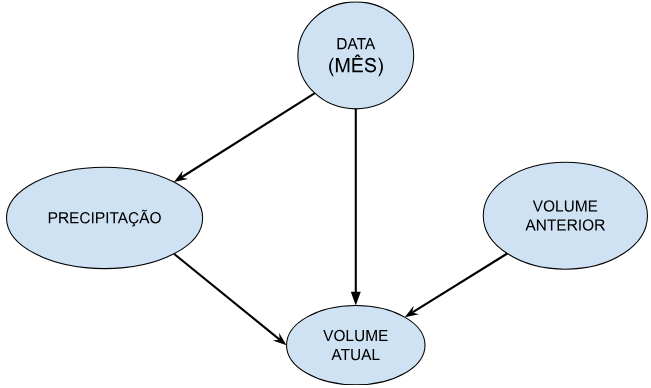

O grafo é aciclico e o volume atual, que é a variável dependente, é o único nó que recebe setas de todos os outros.

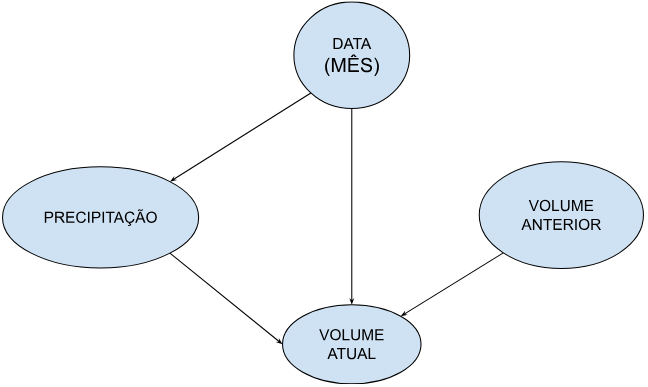

# 4. Realize o ajuste da Rede Bayesiana, considerando o Estimador Bayesiano. Interprete a distribuição de verossimilhança/condicional da variável dependente;

5. Realize a predição da variável dependente de acordo com o modelo para ao menos as últimas 5 linhas do seu conjunto de dados. Analise a qualidade das predições.

6. Em cada seção, interprete seus resultados.